In [1]:
%load_ext autoreload
%autoreload 2
import sys
import os

from pathlib import Path
from omegaconf import OmegaConf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
#PROJECT_ROOT = Path(__file__).resolve().parent.parent if "__file__" in locals() else Path.cwd()


# Ensure project root is on sys.path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.visualization import plot_images, quant_norm, sar_false_color
from datasets import (
    CashewPlantationDataset,
    C2SegDataset,
    ReBEN7kDataset,
    MMHunanDataset
)
from datasets import ReBENDataset

# Helper to load dataset paths from configs/paths/local.yaml for a specific sensor
local_paths_file = PROJECT_ROOT / "configs" / "paths" / "local.yaml"

def get_paths(sensor: str):
    cfg = OmegaConf.load(local_paths_file)
    cfg = OmegaConf.merge(OmegaConf.create({"sensor": sensor}), cfg)
    return OmegaConf.to_container(cfg, resolve=True)


def prepare_vis_img(img, sensor, bands, sar_mode="mean"):
    """Extracts (H, W, 3) visual composite for plotting (RGB for S2, false-color for S1)."""
    if sensor == "S1":
        return sar_false_color(img, bands, mode=sar_mode)
    else:
        # True-color RGB: [B04, B03, B02]
        rgb_indices = [bands.index(b) for b in ["B04", "B03", "B02"]]
        return img[..., rgb_indices]


# Helper Functions: inspect_data
def inspect_data(samples, masks, split_file=None, sensor=None):
    """Prints metadata, dimensions, value ranges, and class distributions for a dataset."""
    if split_file is not None and Path(split_file).exists():
        df = pd.read_csv(split_file)
        print("--- Splits file info ---")
        print("  Column names:", list(df.columns))
        unique_values = df['split'].unique()
        print(f"  Unique values in column `split`: {unique_values}")
        for column_value in unique_values:
            print(f"    Number of entries in '{column_value}': {len(df[df['split'] == column_value])}")

    sensor_str = f" ({sensor})" if sensor else ""
    print(f"\n--- Loaded data info{sensor_str} ---")
    print(f"  Number of samples loaded: {len(samples)}")
    if len(samples) == 0:
        print("  No data loaded.\n")
        return

    t_sample = samples[0]
    m_sample = masks[0]
    
    all_masks = np.concatenate([m.flatten() for m in masks])
    t_min = min(float(t.min()) for t in samples)
    t_max = max(float(t.max()) for t in samples)
    t_mean = float(np.mean([t.mean() for t in samples]))

    print(f"  Tile shape: {t_sample.shape}, dtype: {t_sample.dtype}")
    print(f"  Mask shape: {m_sample.shape}, dtype: {m_sample.dtype}")
    
    print(f"\n--- Data Value Ranges{sensor_str} ---")
    print(f"  Min = {t_min:.4f}, Max = {t_max:.4f}, Mean = {t_mean:.4f}")
    
    unique_vals, counts = np.unique(all_masks, return_counts=True)
    print(f"\n--- Mask Values & Class Distribution{sensor_str} ---")
    total_pixels = len(all_masks)
    for val, count in zip(unique_vals, counts):
        percentage = (count / total_pixels) * 100
        print(f"  Class {val:3d} -> Count: {count:<10} ({percentage:6.2f}%)")
    print()


# ReBEN-7k

--- Splits file info ---
  Column names: ['patch_id', 'split', 's1_name']
  Unique values in column `split`: <StringArray>
['Austria', 'Ireland', 'train', 'validation', 'ood', 'test']
Length: 6, dtype: str
    Number of entries in 'Austria': 8176
    Number of entries in 'Ireland': 13157
    Number of entries in 'train': 4690
    Number of entries in 'validation': 946
    Number of entries in 'ood': 807
    Number of entries in 'test': 945

--- Loaded data info (S2) ---
  Number of samples loaded: 946
  Tile shape: (120, 120, 12), dtype: int16
  Mask shape: (120, 120), dtype: int8

--- Data Value Ranges (S2) ---
  Min = 1.0000, Max = 19104.0000, Mean = 1439.4896

--- Mask Values & Class Distribution (S2) ---
  Class  -1 -> Count: 54961      (  0.40%)
  Class   0 -> Count: 499284     (  3.67%)
  Class   1 -> Count: 161295     (  1.18%)
  Class   2 -> Count: 1825804    ( 13.40%)
  Class   3 -> Count: 633009     (  4.65%)
  Class   4 -> Count: 525116     (  3.85%)
  Class   5 -> Count: 86

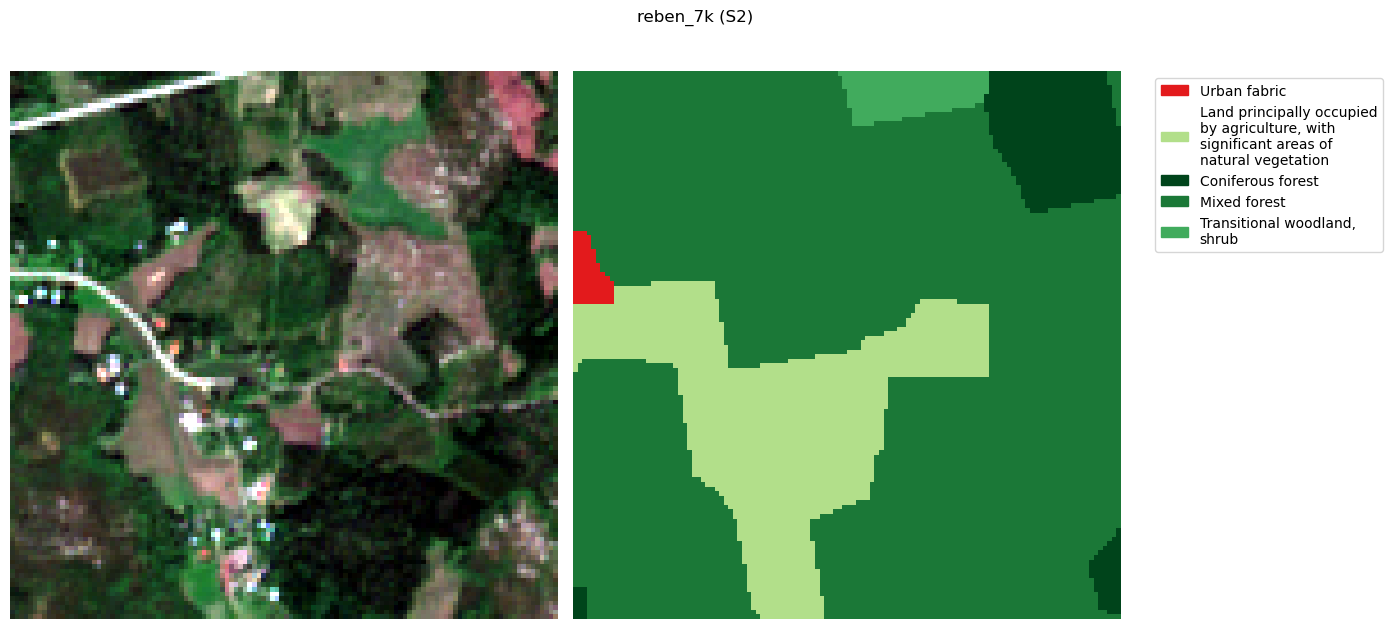


--- Loaded data info (S1) ---
  Number of samples loaded: 946
  Tile shape: (120, 120, 2), dtype: int16
  Mask shape: (120, 120), dtype: int8

--- Data Value Ranges (S1) ---
  Min = -56.0000, Max = 32.0000, Mean = -15.0928

--- Mask Values & Class Distribution (S1) ---
  Class  -1 -> Count: 54961      (  0.40%)
  Class   0 -> Count: 499284     (  3.67%)
  Class   1 -> Count: 161295     (  1.18%)
  Class   2 -> Count: 1825804    ( 13.40%)
  Class   3 -> Count: 633009     (  4.65%)
  Class   4 -> Count: 525116     (  3.85%)
  Class   5 -> Count: 869541     (  6.38%)
  Class   6 -> Count: 769799     (  5.65%)
  Class   7 -> Count: 459195     (  3.37%)
  Class   8 -> Count: 1173350    (  8.61%)
  Class   9 -> Count: 1580432    ( 11.60%)
  Class  10 -> Count: 1391406    ( 10.21%)
  Class  11 -> Count: 191242     (  1.40%)
  Class  12 -> Count: 376742     (  2.77%)
  Class  13 -> Count: 1074468    (  7.89%)
  Class  14 -> Count: 96818      (  0.71%)
  Class  15 -> Count: 134075     (  0.98%

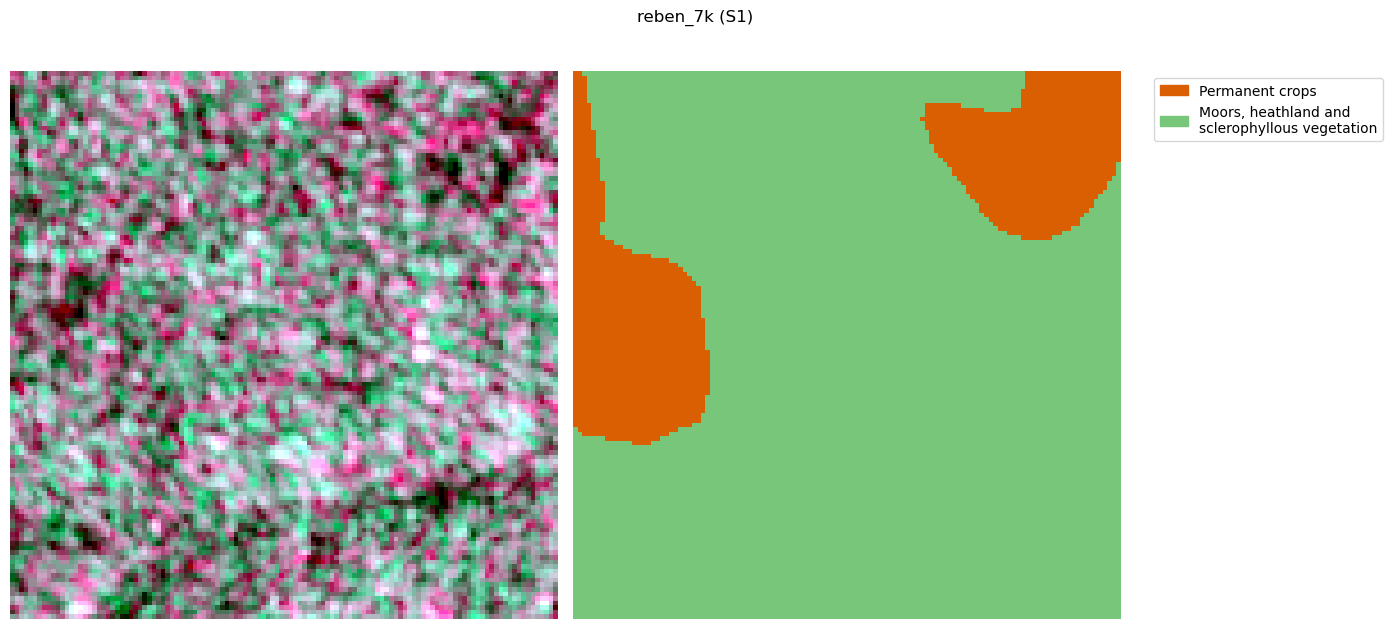

In [2]:
dataset_name = "reben_7k"
split_file = PROJECT_ROOT / "datasets" / "splits" / f"{dataset_name}.csv"

for sensor in ["S2", "S1"]:
    paths = get_paths(sensor)
    data_dir = paths["reben_7k_dir"]
    keys_path = paths["reben_keys"]
    bands = ReBENDataset.S2_BANDS if sensor == "S2" else ReBENDataset.S1_BANDS

    ds_rb = ReBEN7kDataset(
        data_dir=data_dir,
        split_file=str(split_file),
        split="validation",
        keys_path=keys_path,
        grid_sampling=False,
        normalize=False,
        sensor=sensor,
        bands=bands
    )
    inspect_data(ds_rb.samples, ds_rb.masks, split_file=split_file if sensor == "S2" else None, sensor=sensor)

    if len(ds_rb.samples) > 0:
        sample_idx = min(4, len(ds_rb.samples) - 1)
        vis_img = prepare_vis_img(ds_rb.samples[sample_idx], sensor, bands)
        plot_images([quant_norm(vis_img), ds_rb.masks[sample_idx]],
                    title=f"{dataset_name} ({sensor})", dataset_name=dataset_name)


# Cashew Plantation

--- Splits file info ---
  Column names: ['patch_id', 'split']
  Unique values in column `split`: <StringArray>
['train', 'validation', 'test']
Length: 3, dtype: str
    Number of entries in 'train': 1450
    Number of entries in 'validation': 225
    Number of entries in 'test': 125

--- Loaded data info (S2) ---
  Number of samples loaded: 225
  Tile shape: (256, 256, 12), dtype: float32
  Mask shape: (256, 256), dtype: int8

--- Data Value Ranges (S2) ---
  Min = 132.0000, Max = 11900.0000, Mean = 1749.0259

--- Mask Values & Class Distribution (S2) ---
  Class  -1 -> Count: 271950     (  1.84%)
  Class   0 -> Count: 2026225    ( 13.74%)
  Class   1 -> Count: 3852975    ( 26.13%)
  Class   2 -> Count: 2015925    ( 13.67%)
  Class   3 -> Count: 137775     (  0.93%)
  Class   4 -> Count: 6340125    ( 43.00%)
  Class   5 -> Count: 100625     (  0.68%)



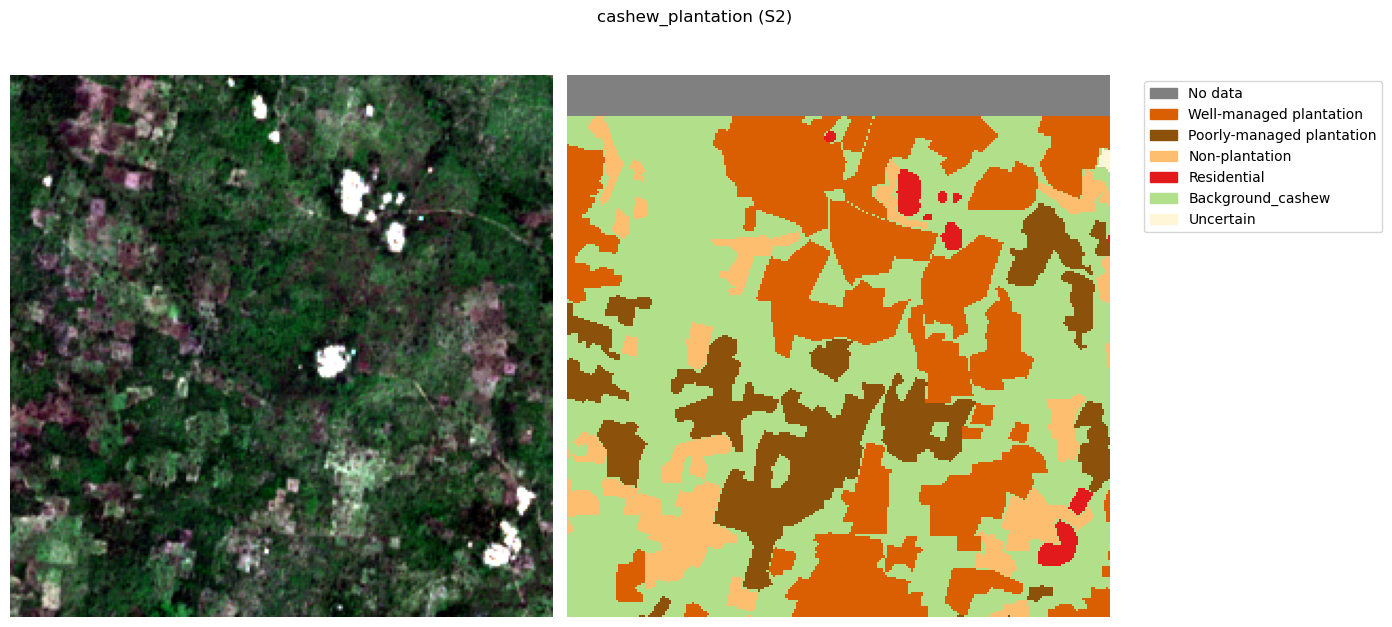


--- Loaded data info (S1) ---
  Number of samples loaded: 225
  Tile shape: (256, 256, 2), dtype: float32
  Mask shape: (256, 256), dtype: int8

--- Data Value Ranges (S1) ---
  Min = -76.9401, Max = 1.7019, Mean = -13.1887

--- Mask Values & Class Distribution (S1) ---
  Class  -1 -> Count: 271950     (  1.84%)
  Class   0 -> Count: 2026225    ( 13.74%)
  Class   1 -> Count: 3852975    ( 26.13%)
  Class   2 -> Count: 2015925    ( 13.67%)
  Class   3 -> Count: 137775     (  0.93%)
  Class   4 -> Count: 6340125    ( 43.00%)
  Class   5 -> Count: 100625     (  0.68%)



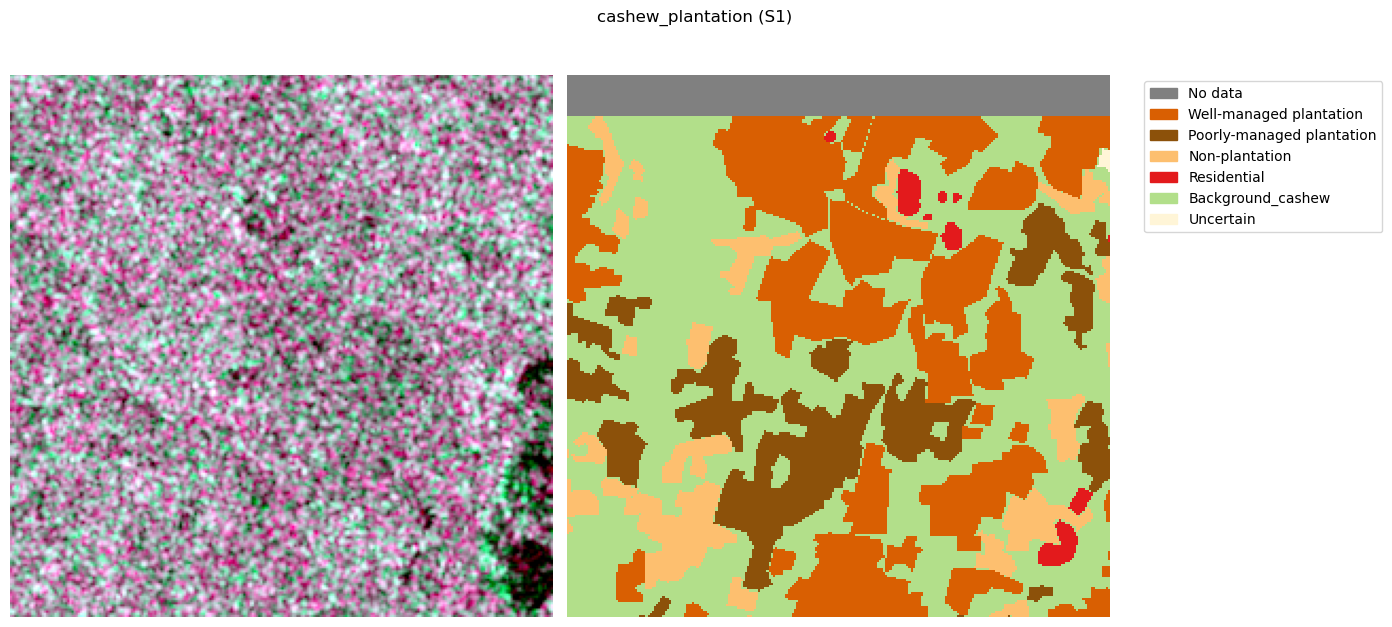

In [3]:
dataset_name = "cashew_plantation"
split_file = PROJECT_ROOT / "datasets" / "splits" / f"{dataset_name}.csv"

for sensor in ["S2", "S1"]:
    paths = get_paths(sensor)
    data_dir = paths["cashew_benin_dir"] if sensor == "S1" else paths["cashew_plantation_dir"]
    bands = ["VH", "VV"] if sensor == "S1" else ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]

    ds_cp = CashewPlantationDataset(
        data_dir=data_dir,
        split_file=str(split_file),
        split="validation",
        sensor=sensor,
        bands=bands,
        grid_sampling=False
    )
    inspect_data(ds_cp.samples, ds_cp.masks, split_file=split_file if sensor == "S2" else None, sensor=sensor)

    if len(ds_cp.samples) > 0:
        vis_img = prepare_vis_img(ds_cp.samples[0], sensor, bands)
        plot_images([quant_norm(vis_img), ds_cp.masks[0]],
                    title=f"{dataset_name} ({sensor})", dataset_name=dataset_name)


# C2Seg AB


--- Loaded data info (S2) ---
  Number of samples loaded: 1
  Tile shape: (177, 1360, 4), dtype: int16
  Mask shape: (177, 1360), dtype: int8

--- Data Value Ranges (S2) ---
  Min = 0.0000, Max = 5514.0000, Mean = 1336.8938

--- Mask Values & Class Distribution (S2) ---
  Class  -1 -> Count: 3879       (  1.61%)
  Class   0 -> Count: 3002       (  1.25%)
  Class   1 -> Count: 21040      (  8.74%)
  Class   2 -> Count: 41935      ( 17.42%)
  Class   3 -> Count: 36455      ( 15.14%)
  Class   4 -> Count: 4301       (  1.79%)
  Class   5 -> Count: 12695      (  5.27%)
  Class   6 -> Count: 74413      ( 30.91%)
  Class   7 -> Count: 2195       (  0.91%)
  Class   8 -> Count: 15523      (  6.45%)
  Class   9 -> Count: 14283      (  5.93%)
  Class  10 -> Count: 8228       (  3.42%)
  Class  11 -> Count: 97         (  0.04%)
  Class  12 -> Count: 2674       (  1.11%)



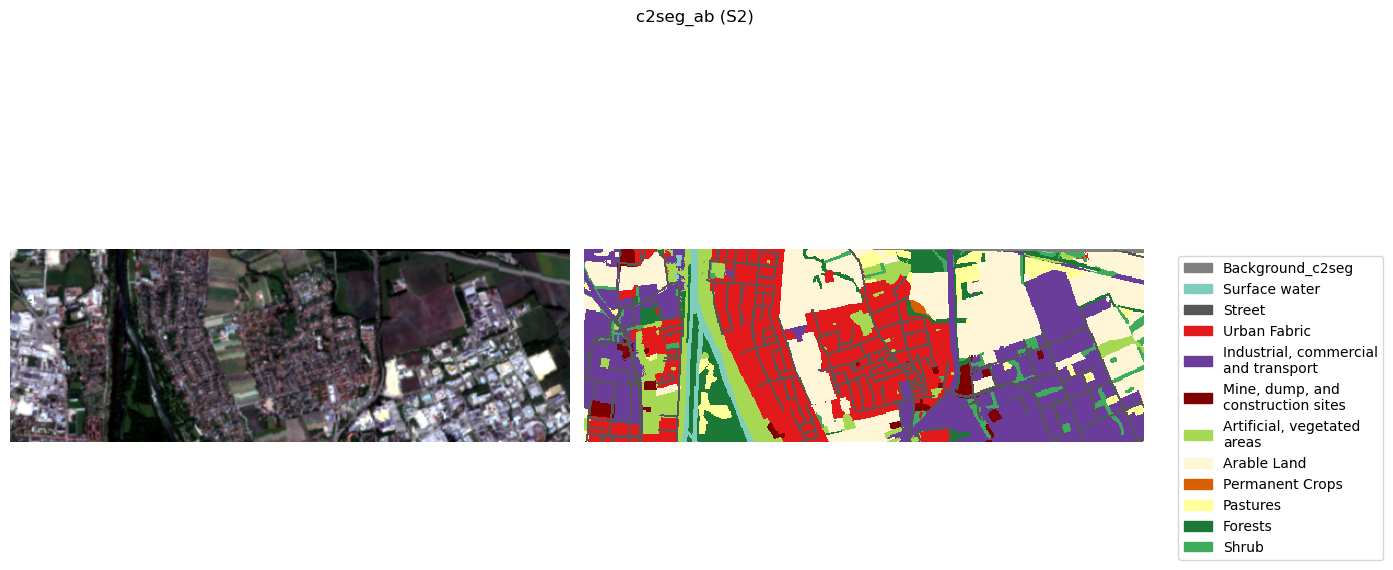


--- Loaded data info (S1) ---
  Number of samples loaded: 1
  Tile shape: (177, 1360, 2), dtype: float32
  Mask shape: (177, 1360), dtype: int8

--- Data Value Ranges (S1) ---
  Min = -32.6815, Max = 25.7281, Mean = -13.7106

--- Mask Values & Class Distribution (S1) ---
  Class  -1 -> Count: 3879       (  1.61%)
  Class   0 -> Count: 3002       (  1.25%)
  Class   1 -> Count: 21040      (  8.74%)
  Class   2 -> Count: 41935      ( 17.42%)
  Class   3 -> Count: 36455      ( 15.14%)
  Class   4 -> Count: 4301       (  1.79%)
  Class   5 -> Count: 12695      (  5.27%)
  Class   6 -> Count: 74413      ( 30.91%)
  Class   7 -> Count: 2195       (  0.91%)
  Class   8 -> Count: 15523      (  6.45%)
  Class   9 -> Count: 14283      (  5.93%)
  Class  10 -> Count: 8228       (  3.42%)
  Class  11 -> Count: 97         (  0.04%)
  Class  12 -> Count: 2674       (  1.11%)



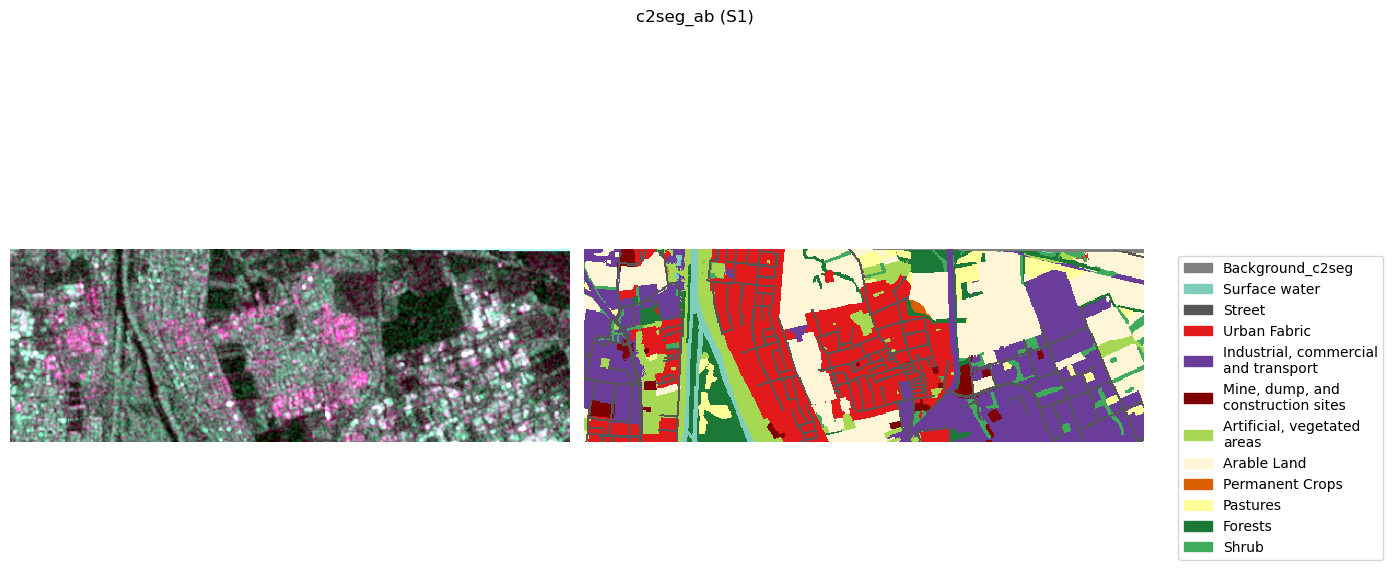

In [4]:
dataset_name = "c2seg_ab"
split_file = PROJECT_ROOT / "datasets" / "splits" / f"{dataset_name}.csv"

for sensor in ["S2", "S1"]:
    paths = get_paths(sensor)
    data_dir = paths["c2seg_dir"]
    bands = ["VH", "VV"] if sensor == "S1" else ["B02", "B03", "B04", "B08"]

    ds_c2_ab = C2SegDataset(
        data_dir=data_dir,
        split_file=split_file,
        split="validation",
        sensor=sensor,
        bands=bands,
        grid_sampling=False
    )
    inspect_data(ds_c2_ab.samples, ds_c2_ab.masks, sensor=sensor)

    if len(ds_c2_ab.samples) > 0:
        sample, mask = ds_c2_ab.samples[0], ds_c2_ab.masks[0]
        H, W = sample.shape[:2]
        h_crop = min(512, H)
        w_crop = min(512, W)
        h_start = (H - h_crop) // 2
        w_start = (W - w_crop) // 2

        vis_crop = prepare_vis_img(sample[h_start:h_start + h_crop, w_start:w_start + w_crop], sensor, bands)
        mask_crop = mask[h_start:h_start + h_crop, w_start:w_start + w_crop]
        plot_images([quant_norm(vis_crop), mask_crop],
                    title=f"{dataset_name} ({sensor})", dataset_name=dataset_name)


# C2Seg BW


--- Loaded data info (S2) ---
  Number of samples loaded: 1
  Tile shape: (13474, 1306, 4), dtype: int16
  Mask shape: (13474, 1306), dtype: int8

--- Data Value Ranges (S2) ---
  Min = -664.0000, Max = 19163.0000, Mean = 889.3209

--- Mask Values & Class Distribution (S2) ---
  Class  -1 -> Count: 329845     (  1.87%)
  Class   0 -> Count: 487689     (  2.77%)
  Class   1 -> Count: 1572974    (  8.94%)
  Class   2 -> Count: 2800624    ( 15.92%)
  Class   3 -> Count: 1600505    (  9.10%)
  Class   4 -> Count: 739855     (  4.20%)
  Class   5 -> Count: 3508544    ( 19.94%)
  Class   6 -> Count: 915694     (  5.20%)
  Class   7 -> Count: 459478     (  2.61%)
  Class   8 -> Count: 35819      (  0.20%)
  Class   9 -> Count: 4740375    ( 26.94%)
  Class  10 -> Count: 169169     (  0.96%)
  Class  11 -> Count: 140556     (  0.80%)
  Class  12 -> Count: 95917      (  0.55%)



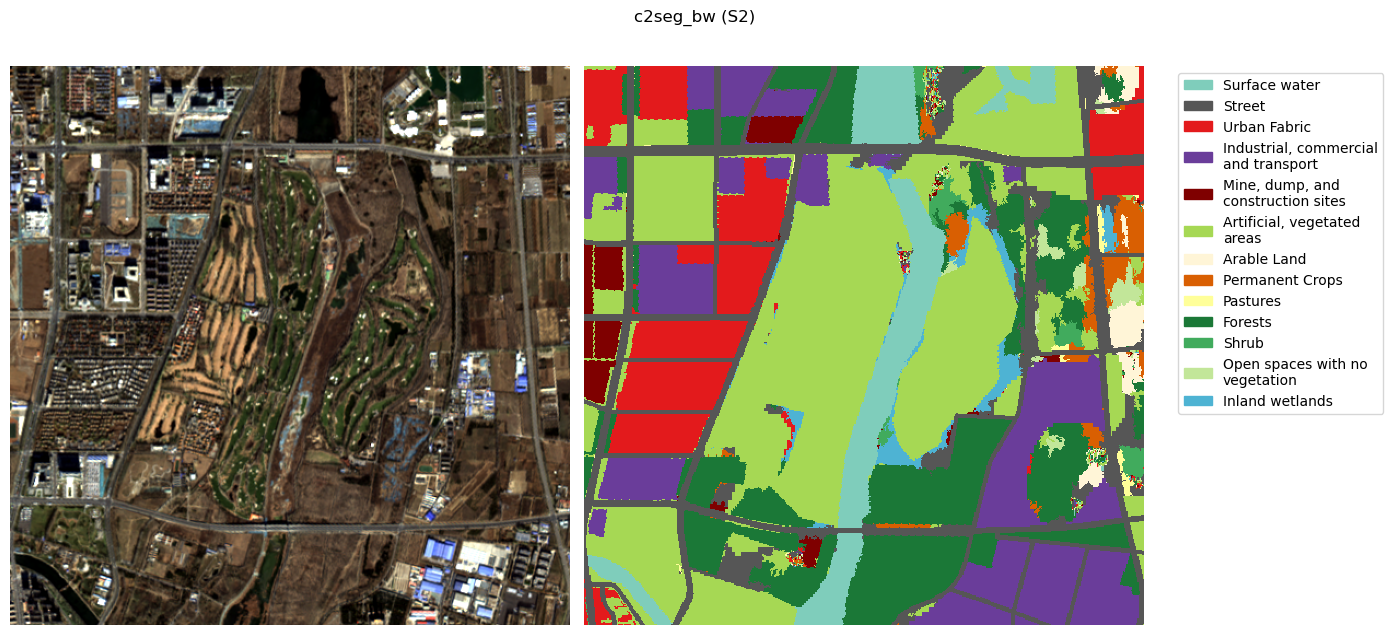


--- Loaded data info (S1) ---
  Number of samples loaded: 1
  Tile shape: (13474, 1306, 2), dtype: float32
  Mask shape: (13474, 1306), dtype: int8

--- Data Value Ranges (S1) ---
  Min = nan, Max = nan, Mean = nan

--- Mask Values & Class Distribution (S1) ---
  Class  -1 -> Count: 329845     (  1.87%)
  Class   0 -> Count: 487689     (  2.77%)
  Class   1 -> Count: 1572974    (  8.94%)
  Class   2 -> Count: 2800624    ( 15.92%)
  Class   3 -> Count: 1600505    (  9.10%)
  Class   4 -> Count: 739855     (  4.20%)
  Class   5 -> Count: 3508544    ( 19.94%)
  Class   6 -> Count: 915694     (  5.20%)
  Class   7 -> Count: 459478     (  2.61%)
  Class   8 -> Count: 35819      (  0.20%)
  Class   9 -> Count: 4740375    ( 26.94%)
  Class  10 -> Count: 169169     (  0.96%)
  Class  11 -> Count: 140556     (  0.80%)
  Class  12 -> Count: 95917      (  0.55%)



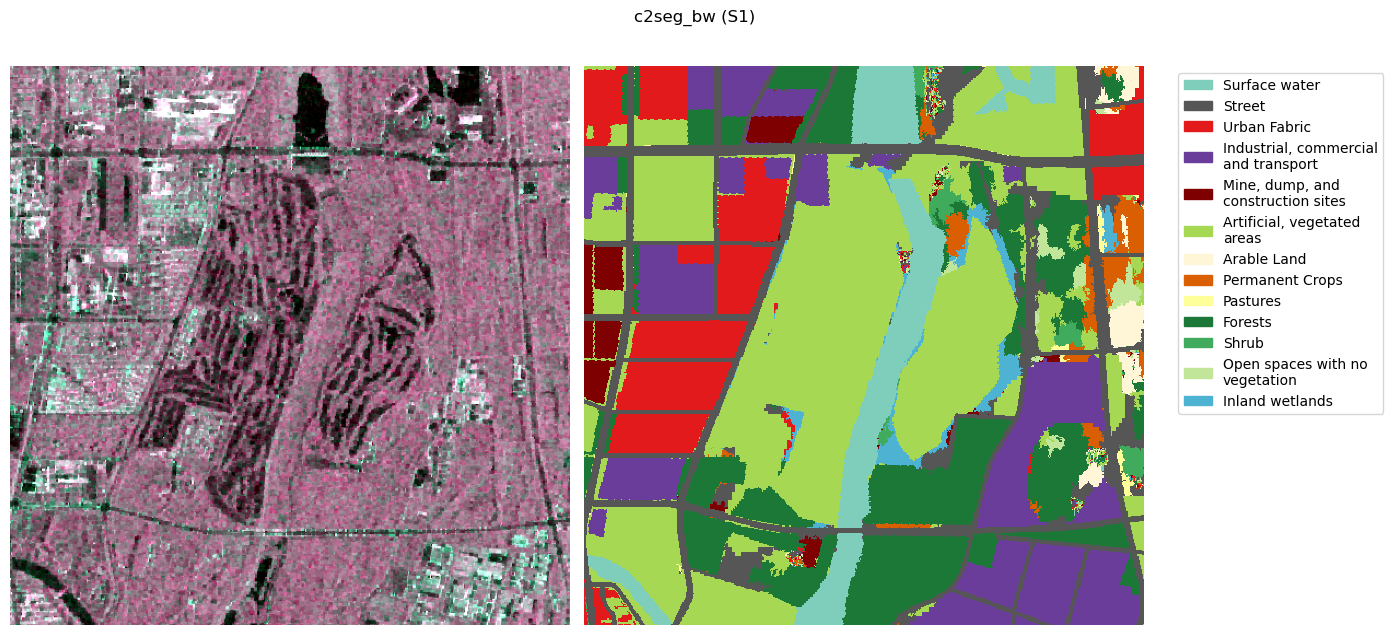

In [5]:
dataset_name = "c2seg_bw"
split_file = PROJECT_ROOT / "datasets" / "splits" / f"{dataset_name}.csv"

for sensor in ["S2", "S1"]:
    paths = get_paths(sensor)
    data_dir = paths["c2seg_dir"]
    bands = ["VH", "VV"] if sensor == "S1" else ["B02", "B03", "B04", "B08"]

    ds_c2_bw = C2SegDataset(
        data_dir=data_dir,
        split_file=split_file,
        split="validation",
        sensor=sensor,
        bands=bands,
        grid_sampling=False
    )
    inspect_data(ds_c2_bw.samples, ds_c2_bw.masks, sensor=sensor)

    if len(ds_c2_bw.samples) > 0:
        sample, mask = ds_c2_bw.samples[0], ds_c2_bw.masks[0]
        H, W = sample.shape[:2]
        h_crop = min(512, H)
        w_crop = min(512, W)
        h_start = (H - h_crop) // 2
        w_start = (W - w_crop) // 2

        vis_crop = prepare_vis_img(sample[h_start:h_start + h_crop, w_start:w_start + w_crop], sensor, bands)
        mask_crop = mask[h_start:h_start + h_crop, w_start:w_start + w_crop]
        plot_images([quant_norm(vis_crop), mask_crop],
                    title=f"{dataset_name} ({sensor})", dataset_name=dataset_name)


# MMHunan

--- Splits file info ---
  Column names: ['patch_id', 'split']
  Unique values in column `split`: <StringArray>
['train', 'validation', 'test']
Length: 3, dtype: str
    Number of entries in 'train': 400
    Number of entries in 'validation': 50
    Number of entries in 'test': 50

--- Loaded data info (S2) ---
  Number of samples loaded: 50
  Tile shape: (256, 256, 13), dtype: int16
  Mask shape: (256, 256), dtype: int8

--- Data Value Ranges (S2) ---
  Min = -30.0000, Max = 15689.0000, Mean = 1258.5900

--- Mask Values & Class Distribution (S2) ---
  Class  -1 -> Count: 1836       (  0.06%)
  Class   0 -> Count: 834693     ( 25.47%)
  Class   1 -> Count: 1218320    ( 37.18%)
  Class   2 -> Count: 289304     (  8.83%)
  Class   3 -> Count: 73843      (  2.25%)
  Class   4 -> Count: 442097     ( 13.49%)
  Class   5 -> Count: 40495      (  1.24%)
  Class   6 -> Count: 376212     ( 11.48%)



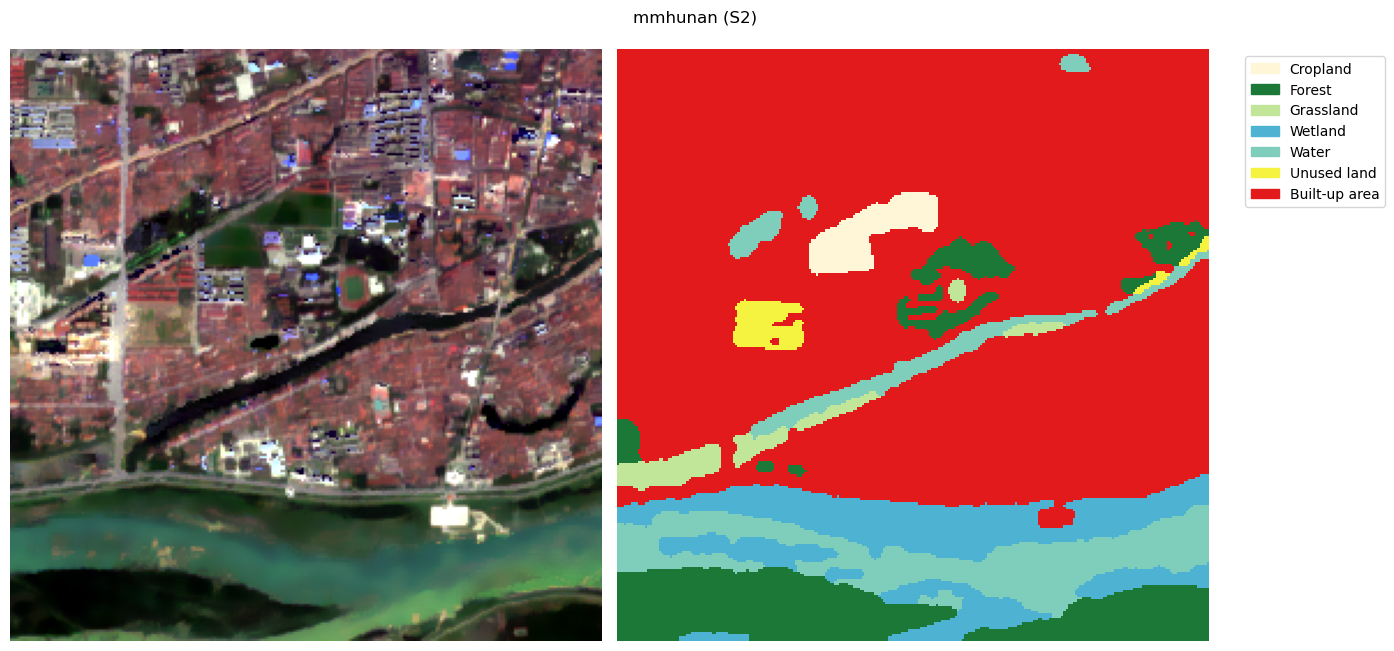


--- Loaded data info (S1) ---
  Number of samples loaded: 50
  Tile shape: (256, 256, 2), dtype: float32
  Mask shape: (256, 256), dtype: int8

--- Data Value Ranges (S1) ---
  Min = -50.0317, Max = 21.7516, Mean = -13.3819

--- Mask Values & Class Distribution (S1) ---
  Class  -1 -> Count: 1836       (  0.06%)
  Class   0 -> Count: 834693     ( 25.47%)
  Class   1 -> Count: 1218320    ( 37.18%)
  Class   2 -> Count: 289304     (  8.83%)
  Class   3 -> Count: 73843      (  2.25%)
  Class   4 -> Count: 442097     ( 13.49%)
  Class   5 -> Count: 40495      (  1.24%)
  Class   6 -> Count: 376212     ( 11.48%)



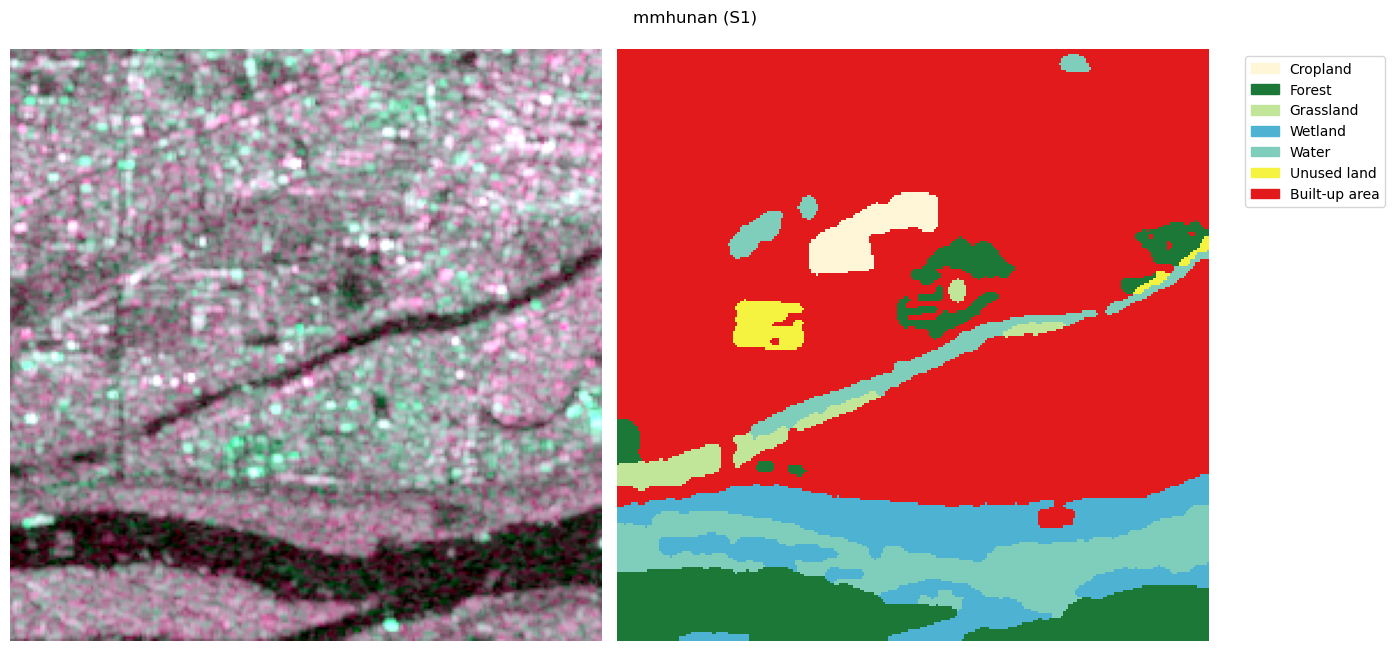

In [6]:
dataset_name = "mmhunan"
split_file = PROJECT_ROOT / "datasets" / "splits" / f"{dataset_name}.csv"

for sensor in ["S2", "S1"]:
    paths = get_paths(sensor)
    data_dir = paths["mmhunan_dir"]
    bands = ["VH", "VV"] if sensor == "S1" else ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]

    ds_mh = MMHunanDataset(
        data_dir=data_dir,
        split_file=str(split_file),
        split="validation",
        sensor=sensor,
        bands=bands,
        grid_sampling=False
    )
    inspect_data(ds_mh.samples, ds_mh.masks, split_file=split_file if sensor == "S2" else None, sensor=sensor)

    if len(ds_mh.samples) > 0:
        vis_img = prepare_vis_img(ds_mh.samples[0], sensor, bands)
        plot_images([quant_norm(vis_img), ds_mh.masks[0]],
                    title=f"{dataset_name} ({sensor})", dataset_name=dataset_name)
